# Training dynamics

> Record how each layer's weights, gradients and activations change while the CNN trains: on OSSL, on Fukushima from random weights, and when fine-tuning on Fukushima

In [ ]:
#| default_exp dynamics

In [ ]:
#| export
import copy, pickle
import matplotlib.pyplot as plt
import numpy as np, pandas as pd, torch
from fastai.callback.core import Callback
from fastai.callback.hook import ActivationStats
import fastai.callback.schedule
from soilspecdl.all import spectral_learner, BatchSNV, TensorSpectrum
from ossl_fuku_transfer.data import shared_wns
from ossl_fuku_transfer.transfer import model_dir

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [ ]:
import copy
from fastcore.test import *
from fastai.torch_core import set_seed
from soilspecdata.all import load_ossl
from soilspecdl.all import get_spectral_dls, get_splitter, BatchSNV
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *

The module part uses small random arrays, so it runs without the data. The sections from *OSSL pretraining* onwards read OSSL and the Fukushima data, and are marked `#| fukudata`.

## Recording

`param_label` turns a parameter name of `new_model` into a short label. Each block has a convolution, then batch norm with scale γ and shift β:

In [ ]:
#| export
def param_label(name:str)->str: # Such as 'block 1 conv', 'block 1 BN γ' or 'head W'
    "Short label for the parameter `name` of a `SpectralCNN`"
    p = name.split('.')
    if p[0] == 'head': return 'head W' if p[-1] == 'weight' else 'head b'
    kind = 'conv' if p[4] == '0' else ('BN γ' if p[-1] == 'weight' else 'BN β')
    return f'block {int(p[2]) + 1} {kind}'

In [ ]:
labels = [param_label(n) for n, _ in new_model().named_parameters()]
test_eq(labels[:4], ['block 1 conv', 'block 1 BN γ', 'block 1 BN β', 'block 2 conv'])
test_eq(labels[-2:], ['head W', 'head b'])
len(labels)

17

`ParamStats` records, every `every` training steps and for each parameter tensor:

- `weight`: the norm ‖W‖;
- `grad`: the norm of the gradient;
- `update`: the size of this step relative to the weights, ‖ΔW‖/‖W‖;
- `moved`: how far the weights are from where the fit started, ‖W − W₀‖/‖W₀‖.

A relative update near 10⁻³ is a common rule of thumb for a layer that learns at a sensible rate. Much smaller means the layer barely learns, and much larger means it is unstable.

Adam scales each element's step by the history of its own gradients, so the step per element is similar across layers. The default initialisation sets a layer's weights to a scale of about 1/√(fan-in), the number of inputs to each unit. So with the same learning rate, ‖ΔW‖/‖W‖ grows with √(fan-in). In `new_model`, the fan-in of the 5 convolutions is 3, 48, 96, 192 and 384. A smaller relative update in block 1 is therefore expected, and doesn't by itself mean that block 1 learns less.

In [ ]:
#| export
class ParamStats(Callback):
    "Record the norm, gradient norm, relative update and relative distance from the start of each parameter, every `every` steps"
    def __init__(self, every=10): self.every = every
    def before_fit(self):
        self.names, self.params = zip(*self.model.named_parameters())
        self.start, self.recs, self._rec = [p.detach().clone() for p in self.params], [], False
    def before_step(self):
        self._rec = self.train_iter % self.every == 0
        if not self._rec: return
        self.prev = [p.detach().clone() for p in self.params]
        self.grad = torch.stack([p.grad.norm() if p.grad is not None else p.new_zeros(()) for p in self.params])
    def after_step(self):
        if not self._rec: return
        norms = lambda qs: torch.stack([(p.detach() - q).norm() for p, q in zip(self.params, qs)])
        w = torch.stack([p.detach().norm() for p in self.params])
        w0 = torch.stack([q.norm() for q in self.start])
        stats = torch.stack([w, self.grad, norms(self.prev) / w, norms(self.start) / w0]).cpu().numpy()
        self.recs.append((self.train_iter, self.opt.hypers[-1]['lr'], stats))
    def after_fit(self):
        "Collect the records in `df`, one row per step and parameter"
        rows = [{'step': s, 'lr': lr, 'param': param_label(n), **dict(zip(('weight', 'grad', 'update', 'moved'), st[:, i]))}
                for s, lr, st in self.recs for i, n in enumerate(self.names)]
        self.df = pd.DataFrame(rows)

`tracked_fit` trains `learn` with a one-cycle schedule while recording `ParamStats` and fastai's `ActivationStats`. The activations are those of each block's convolution, batch norm and LeakyReLU, before pooling. `ActivationStats` gives their mean, standard deviation and `near_zero`, the share of values ≤ 0.05. After LeakyReLU, those are the units that are switched off. The histograms span 0 to 10 in 40 bins.

With `fname`, the record is saved in `model_dir()` and loaded on later calls instead of training again.

In [ ]:
#| export
def _act_arrays(acts)->dict:
    "Mean, std, share ≤ 0.05 and histogram of each hooked module, as arrays of shape (records, modules[, bins])"
    res = {k: np.array([[d[k] for d in s] for s in acts.stats]) for k in ('mean', 'std', 'near_zero')}
    res['hist'] = np.stack([np.stack([d['hist'].numpy() for d in s]) for s in acts.stats])
    return res

def tracked_fit(
    learn, # Learner from `spectral_learner`, with a `SpectralCNN`
    epochs, # Number of one-cycle epochs
    lr, # Maximum learning rate
    every=10, # Record every `every` training steps
    fname=None, # File name for the record, without extension; no file if None
)->dict: # Keys 'params', 'acts', 'history', 'steps_per_epoch' and 'state'
    "Fit `learn` and record its parameter and activation statistics, or load the record saved under `fname`"
    fn = model_dir()/f'{fname}.pkl' if fname else None
    if fn and fn.exists(): return pickle.loads(fn.read_bytes())
    ps = ParamStats(every)
    acts = ActivationStats(modules=[b.conv for b in learn.model.backbone.layers], every=every, with_hist=True)
    with learn.no_bar(), learn.no_logging(): learn.fit_one_cycle(epochs, lr_max=lr, cbs=[ps, acts])
    rec = {'params': ps.df, 'acts': _act_arrays(acts), 'steps_per_epoch': len(learn.dls.train),
           'history': pd.DataFrame(learn.recorder.values, columns=learn.recorder.metric_names[1:-1]),
           'state': {k: v.cpu() for k, v in learn.model.state_dict().items()}}
    if fn: fn.write_bytes(pickle.dumps(rec))
    return rec

In [ ]:
rng = np.random.default_rng(0)
X_syn, y_syn = rng.random((100, len(shared_wns))), rng.random(100)
dls_syn = fuku_dls(X_syn, y_syn, np.arange(100) >= 80)
set_seed(0)
rec_syn = tracked_fit(spectral_learner(dls_syn, new_model()), 2, 1e-3, every=2)
p, steps = rec_syn['params'], list(range(0, 2 * rec_syn['steps_per_epoch'], 2))
test_eq(p.param.nunique(), 17)
test_eq(sorted(p.step.unique()), steps)
test_eq(rec_syn['acts']['hist'].shape, (len(steps), 5, 40))
p.head()

,step,lr,param,weight,grad,update,moved
0,0,0.00004,block 1 conv,5.867114,0.046041,0.000047,0.000047
1,0,0.00004,block 1 BN γ,3.999980,0.033374,0.000040,0.000040
2,0,0.00004,block 1 BN β,0.003983,0.031638,0.040067,0.039900
3,0,0.00004,block 2 conv,7.797356,0.155505,0.000199,0.000199
4,0,0.00004,block 2 BN γ,5.656854,0.035060,0.000040,0.000040


## Plotting

`plot_params` plots statistics of `ParamStats` against the epoch, one line per parameter whose label contains `kind`, plus the head weights. Each line is a rolling mean over `smooth` records, on a log scale:

In [ ]:
#| export
def plot_params(
    rec, # Record from `tracked_fit`
    stats=('update', 'grad', 'moved'), # Columns of `rec['params']` to plot, one panel each
    kind='conv', # Part of the parameter label to select, such as 'conv' or 'BN γ'
    smooth=10, # Window of the rolling mean, in records
):
    "Plot `stats` of each selected parameter over training"
    p, spe = rec['params'], rec['steps_per_epoch']
    sel = p[p.param.str.contains(kind) | (p.param == 'head W')]
    fig, axs = plt.subplots(1, len(stats), figsize=(4 * len(stats), 3), layout='constrained')
    for ax, st in zip(np.atleast_1d(axs), stats):
        for name, g in sel.groupby('param', sort=False):
            ax.plot(g.step / spe, g[st].rolling(smooth, min_periods=1).mean(), lw=0.8, label=name)
        ax.set_yscale('log'); ax.set_title(st); ax.set_xlabel('epoch')
    np.atleast_1d(axs)[0].legend(fontsize=7)
    return axs

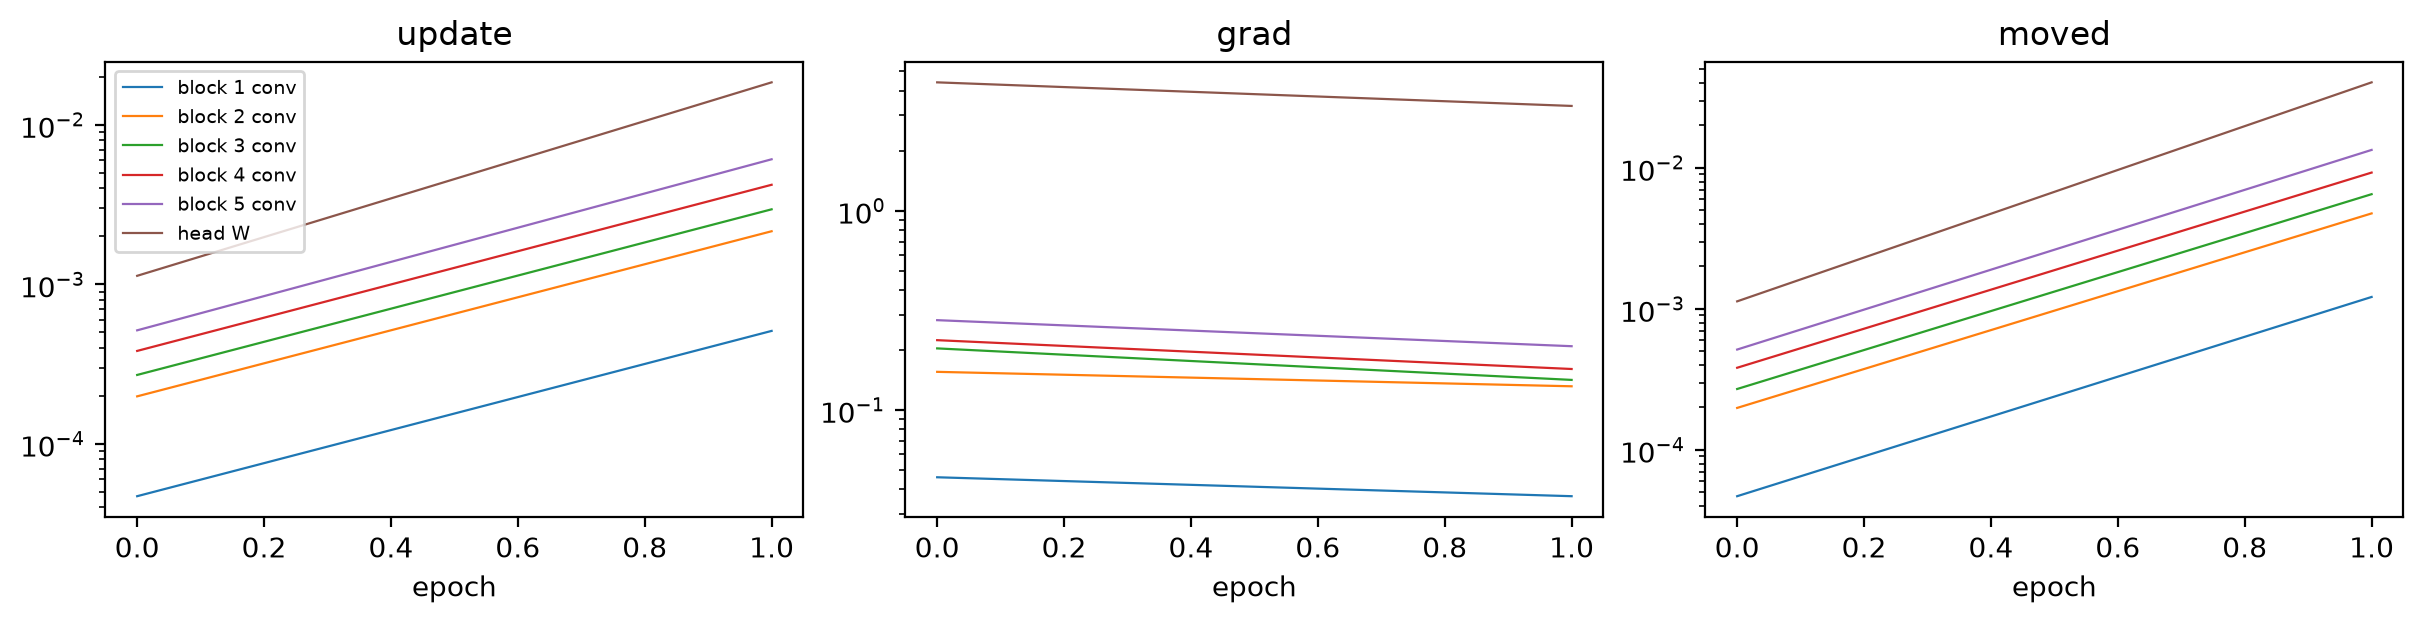

In [ ]:
plot_params(rec_syn, smooth=1);

`plot_acts` plots the activation statistics of each block over training. The second row shows each block's histogram over training, as fastai's `color_dim` does: the colour is the log of the count, and the vertical axis spans activations from 0 to 10:

In [ ]:
#| export
def plot_acts(
    rec, # Record from `tracked_fit`
):
    "Plot the mean, standard deviation, share ≤ 0.05 and histogram of each block's activations over training"
    a, spe = rec['acts'], rec['steps_per_epoch']
    ep = np.sort(rec['params'].step.unique()) / spe
    n = a['mean'].shape[1]
    fig, axs = plt.subplots(2, max(3, n), figsize=(3 * max(3, n), 5.5), layout='constrained')
    for ax, k in zip(axs[0], ('mean', 'std', 'near_zero')):
        for b in range(n): ax.plot(ep, a[k][:, b], lw=0.8, label=f'block {b + 1}')
        ax.set_title(k); ax.set_xlabel('epoch')
    axs[0, 0].legend(fontsize=7)
    for ax in axs[0, 3:]: ax.axis('off')
    for b, ax in enumerate(axs[1]):
        ax.imshow(np.log1p(a['hist'][:, b].T), origin='lower', aspect='auto', extent=(0, ep[-1], 0, 10))
        ax.set_title(f'block {b + 1}'); ax.set_xlabel('epoch')
    axs[1, 0].set_ylabel('activation')
    return axs

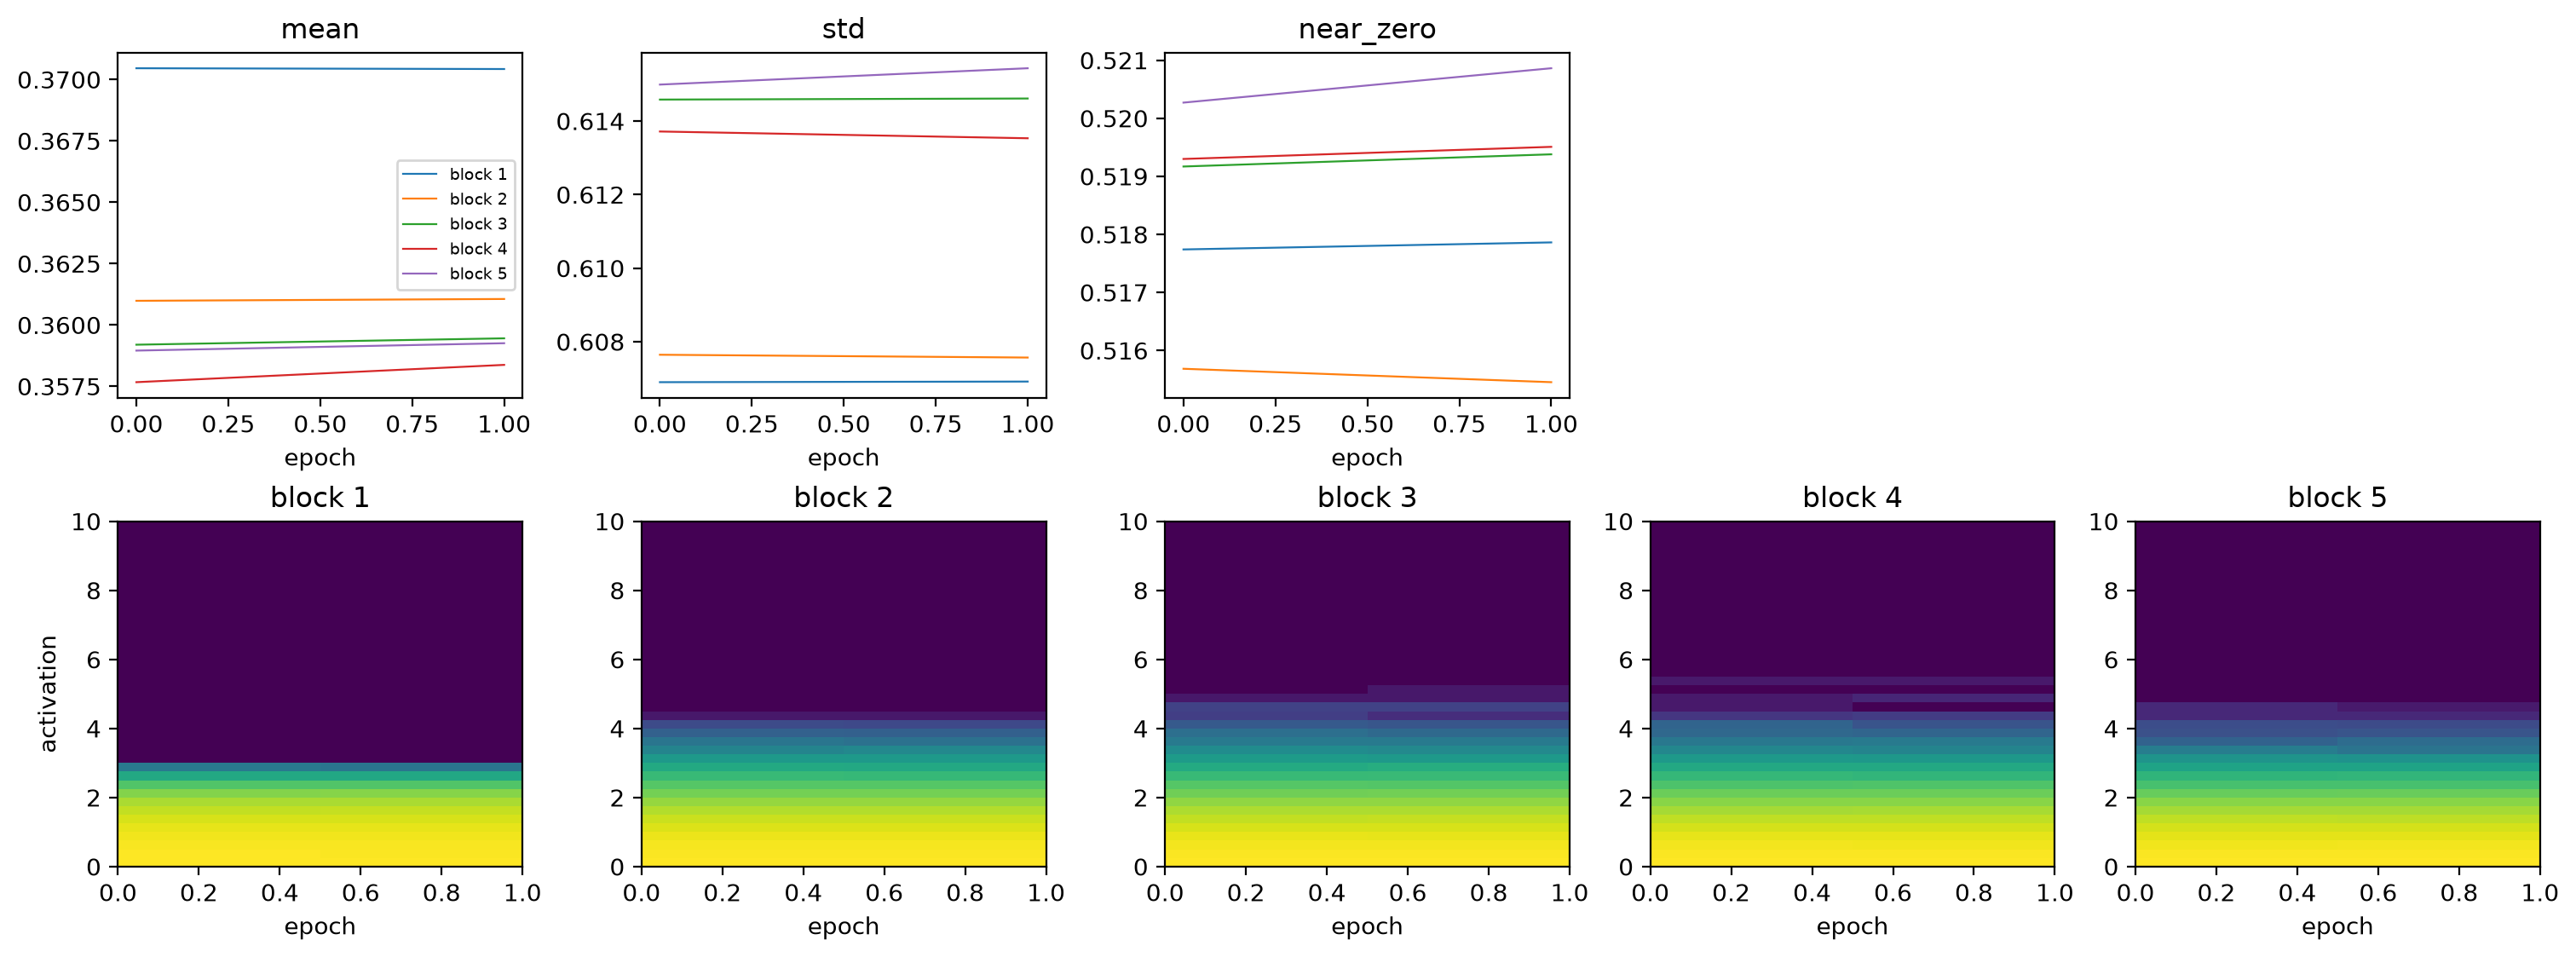

In [ ]:
plot_acts(rec_syn);

## Channel activity

`block_acts` runs spectra through a model block by block, and yields each block's activations before pooling. `channel_activity` gives, for each block of a trained model, the share of spectra and positions at which each channel's activation is above 0.05. A channel that is almost never above it is dead: it passes almost nothing to the next block. A channel that is almost always above it works as a linear unit, since LeakyReLU then never bends its output.

In [ ]:
#| export
def block_acts(
    model, # Trained `SpectralCNN`
    X, # Preprocessed spectra, one per row
    bs=256, # Batch size
):
    "Yield, for each batch of `X`, the activations of each block of `model` before pooling, applying `BatchSNV` first as in training"
    m, snv = copy.deepcopy(model).cpu().eval(), BatchSNV()
    with torch.no_grad():
        for i in range(0, len(X), bs):
            x, acts = snv(TensorSpectrum(torch.tensor(X[i:i+bs], dtype=torch.float32).unsqueeze(1), wns=shared_wns)), []
            for b in m.backbone.layers:
                acts.append(b.conv(x))
                x = b.pool(acts[-1])
            yield acts

def channel_activity(
    model, # Trained `SpectralCNN`
    X, # Preprocessed spectra, one per row
    bs=256, # Batch size
)->list: # One array per block, with one share per channel
    "Share of activations above 0.05 for each channel of each block of `model`, over the spectra in `X` and all positions"
    tot = [sum(t) for t in zip(*[[(a > 0.05).float().mean(2).sum(0) for a in acts] for acts in block_acts(model, X, bs)])]
    return [(t / len(X)).numpy() for t in tot]

def activity_table(
    acts:dict, # Model name, or tuple of names: result of `channel_activity`
    lo=0.01, # A channel is dead below this share
    hi=0.99, # A channel is linear above this share
)->pd.DataFrame:
    "Number of channels per block that are dead, linear, and in total, for each model"
    key = lambda k, b: (*k, b) if isinstance(k, tuple) else (k, b)
    return pd.DataFrame({key(k, b + 1): {'dead': int((c < lo).sum()), 'linear': int((c > hi).sum()), 'channels': len(c)}
                         for k, a in acts.items() for b, c in enumerate(a)}).T

In [ ]:
m_syn = new_model()
m_syn.load_state_dict(rec_syn['state'])
act_syn = channel_activity(m_syn, X_syn)
test_eq([len(c) for c in act_syn], [16, 32, 64, 128, 256])
test_eq(all(((c >= 0) & (c <= 1)).all() for c in act_syn), True)
activity_table({'random data': act_syn})

dead  linear  channels
random data 1     0       0        16
            2     0       0        32
            3     1       2        64
            4    17      12       128
            5    47      33       256

## OSSL pretraining

The data and preprocessing are those of `03_kex`: OSSL MIR spectra with `log1p(Kex)`, SNV and a Savitzky-Golay first derivative fitted on OSSL. The Fukushima spectra get the same preprocessing and the Cs137 test split:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo, _ = om.xy('k.ext_usda.a725_cmolc.kg')
yo = np.log1p(yo.ravel())
fuku = load_fuku()
fuku.source = fuku.source.assign(target=fuku.source['soil_ex_K2O'] / mg_k2o_per_cmolc)
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
is_test = np.isin(idf, cs137_split()[1])
pipe = preprocessings()['snv_d1']
Xo_d, Xf_d = pipe.fit_transform(Xo), pipe.transform(Xf)
Xo_d.shape, Xf_d.shape

((57674, 1675), (1388, 1675))

This run repeats `pretrain('ossl_kex_snv_d1')` with the same split, seed and schedule (20 epochs, learning rate 10⁻³), recording every 10 steps. Training on MPS is not fully deterministic, so its weights differ slightly from the saved pretrained model. The last epoch:

In [ ]:
#| fukudata
dls_o = get_spectral_dls(Xo_d, yo, shared_wns, splitter=get_splitter(0.9, 0.1, seed=42), batch_tfms=[BatchSNV()])[0]
set_seed(42)
runs = {'OSSL': tracked_fit(spectral_learner(dls_o, new_model()), 20, 1e-3, fname='dyn_ossl_kex')}
runs['OSSL']['history'].iloc[-1].round(3).to_dict()

{'train_loss': 0.027, 'valid_loss': 0.03, 'r2_score': 0.792}

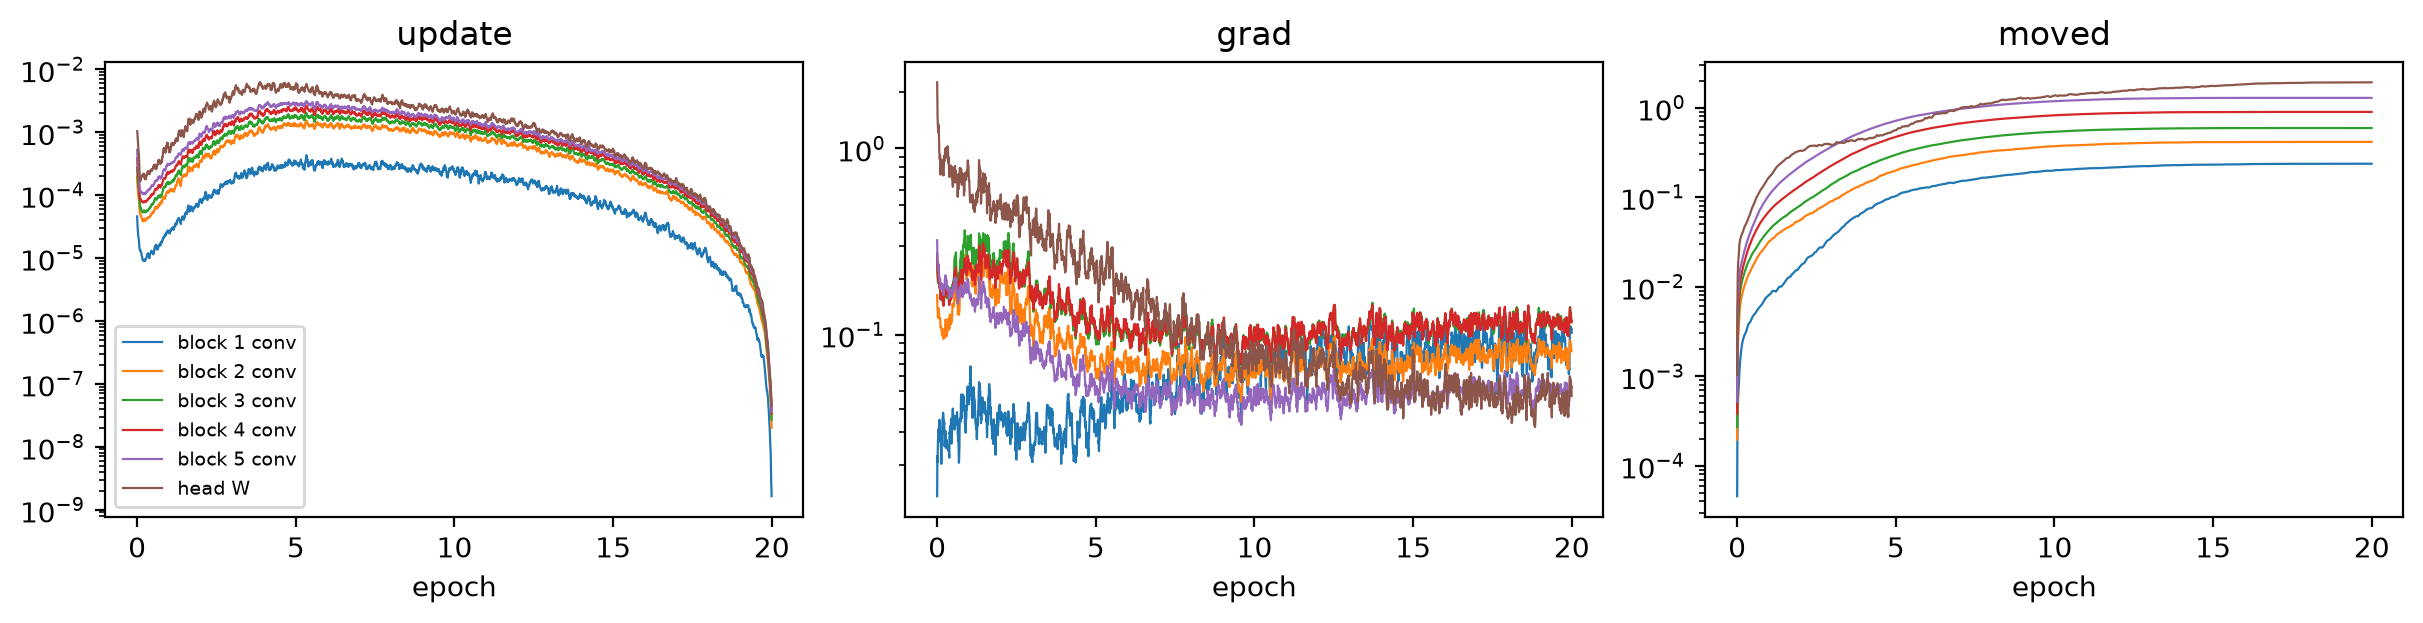

In [ ]:
#| fukudata
plot_params(runs['OSSL']);

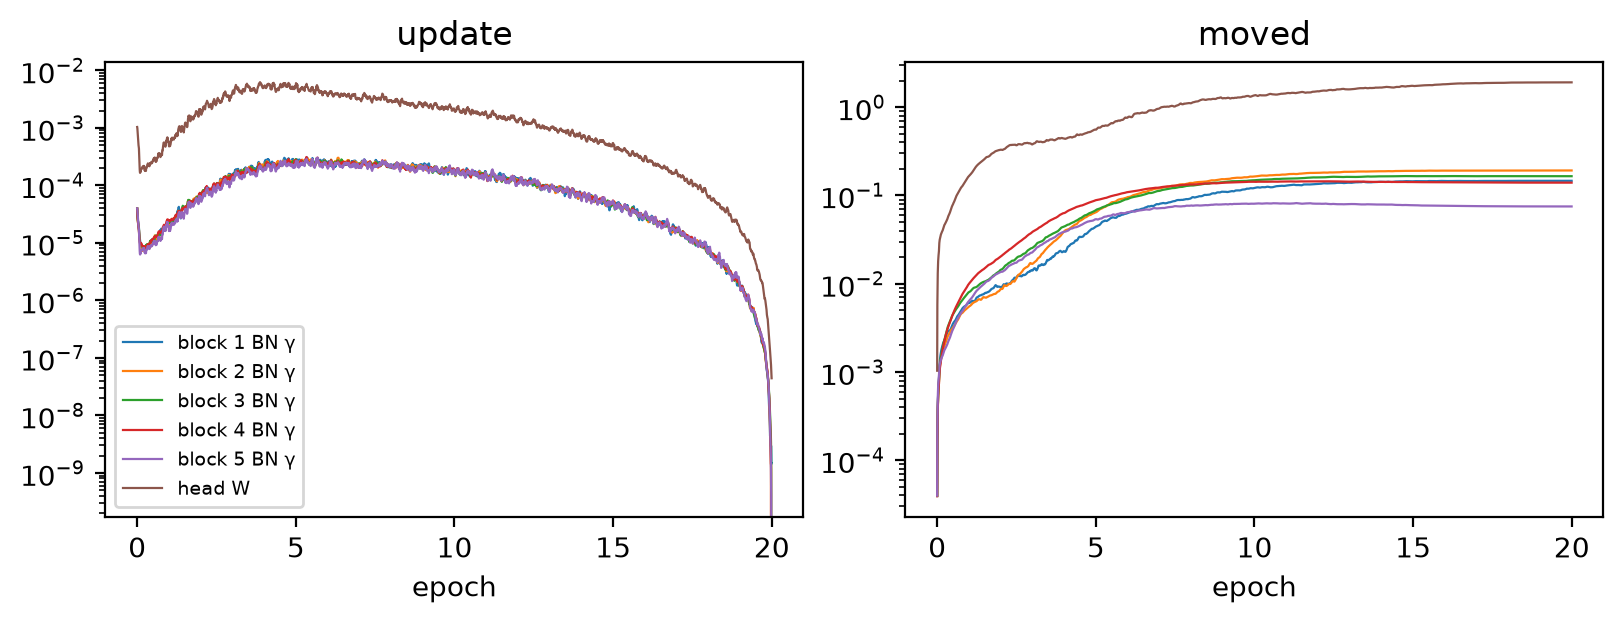

In [ ]:
#| fukudata
plot_params(runs['OSSL'], kind='BN γ', stats=('update', 'moved'));

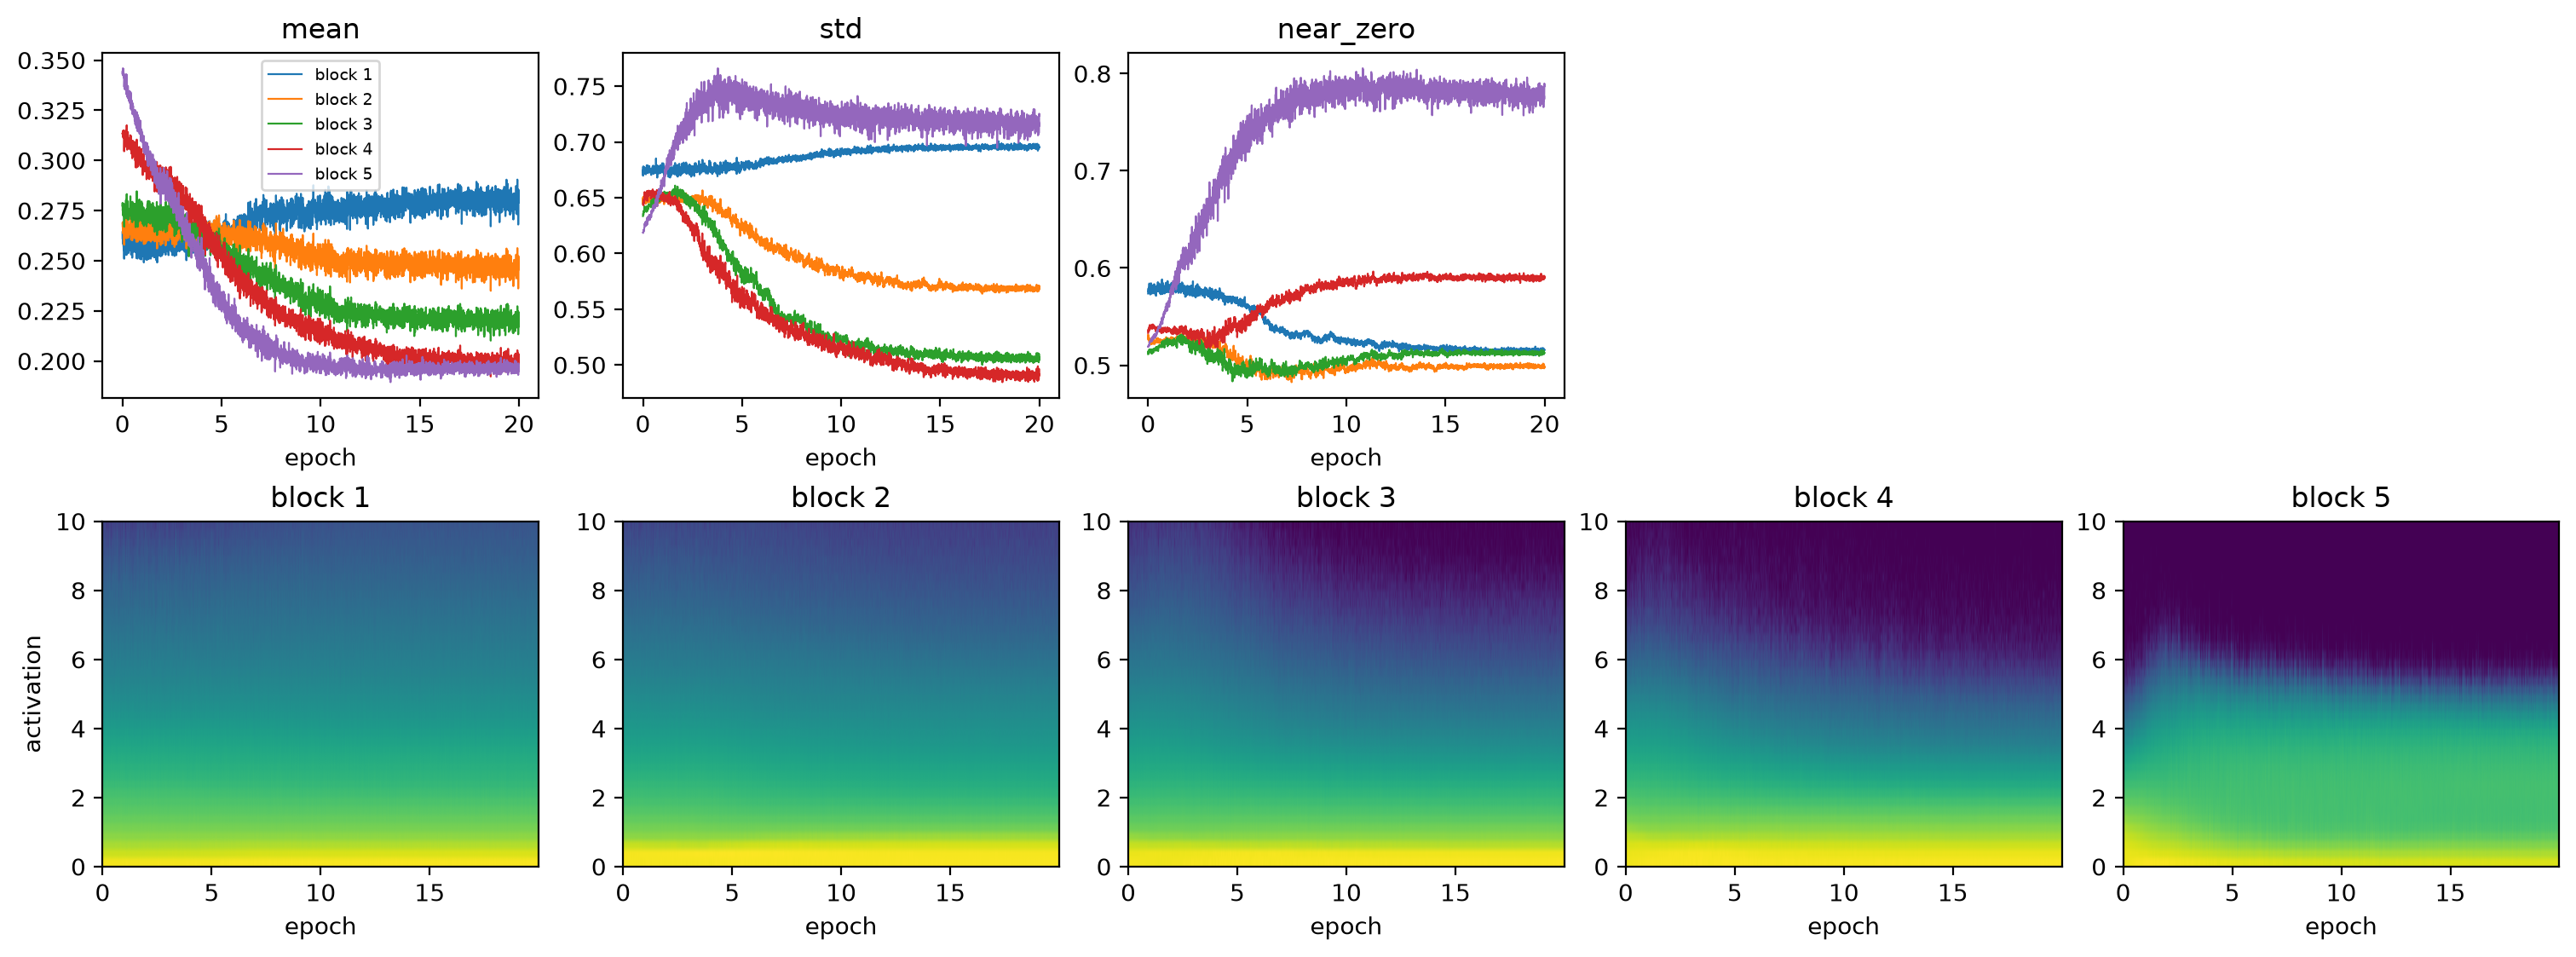

In [ ]:
#| fukudata
plot_acts(runs['OSSL']);

## Fukushima

Two runs on the Fukushima training samples, with the schedules that cross-validation chose in `03_kex`: from random weights (40 epochs, learning rate 3·10⁻³), and fully fine-tuned from the saved pretrained model (20 epochs, 3·10⁻³). Both record every 2 steps. The test scores check that these runs match the comparison in `03_kex`:

In [ ]:
#| fukudata
dls_f = fuku_dls(Xf_d, yf, is_test, seed=0)
set_seed(0)
runs['Fukushima only'] = tracked_fit(spectral_learner(dls_f, new_model()), 40, 3e-3, every=2, fname='dyn_fuku_kex_scratch')
set_seed(0)
pretrained = load_pretrained('ossl_kex_snv_d1')
runs['fully fine-tuned'] = tracked_fit(spectral_learner(dls_f, copy.deepcopy(pretrained)), 20, 3e-3, every=2, fname='dyn_fuku_kex_ft')
models = {}
for k, r in runs.items():
    models[k] = new_model()
    models[k].load_state_dict(r['state'])
pd.DataFrame({k: scores(yf[is_test], predict(models[k], Xf_d[is_test])) for k in ('Fukushima only', 'fully fine-tuned')}).round(3)

,Fukushima only,fully fine-tuned
R²,0.377,0.426
r,0.616,0.655
RMSE,0.316,0.303
bias,-0.037,-0.035


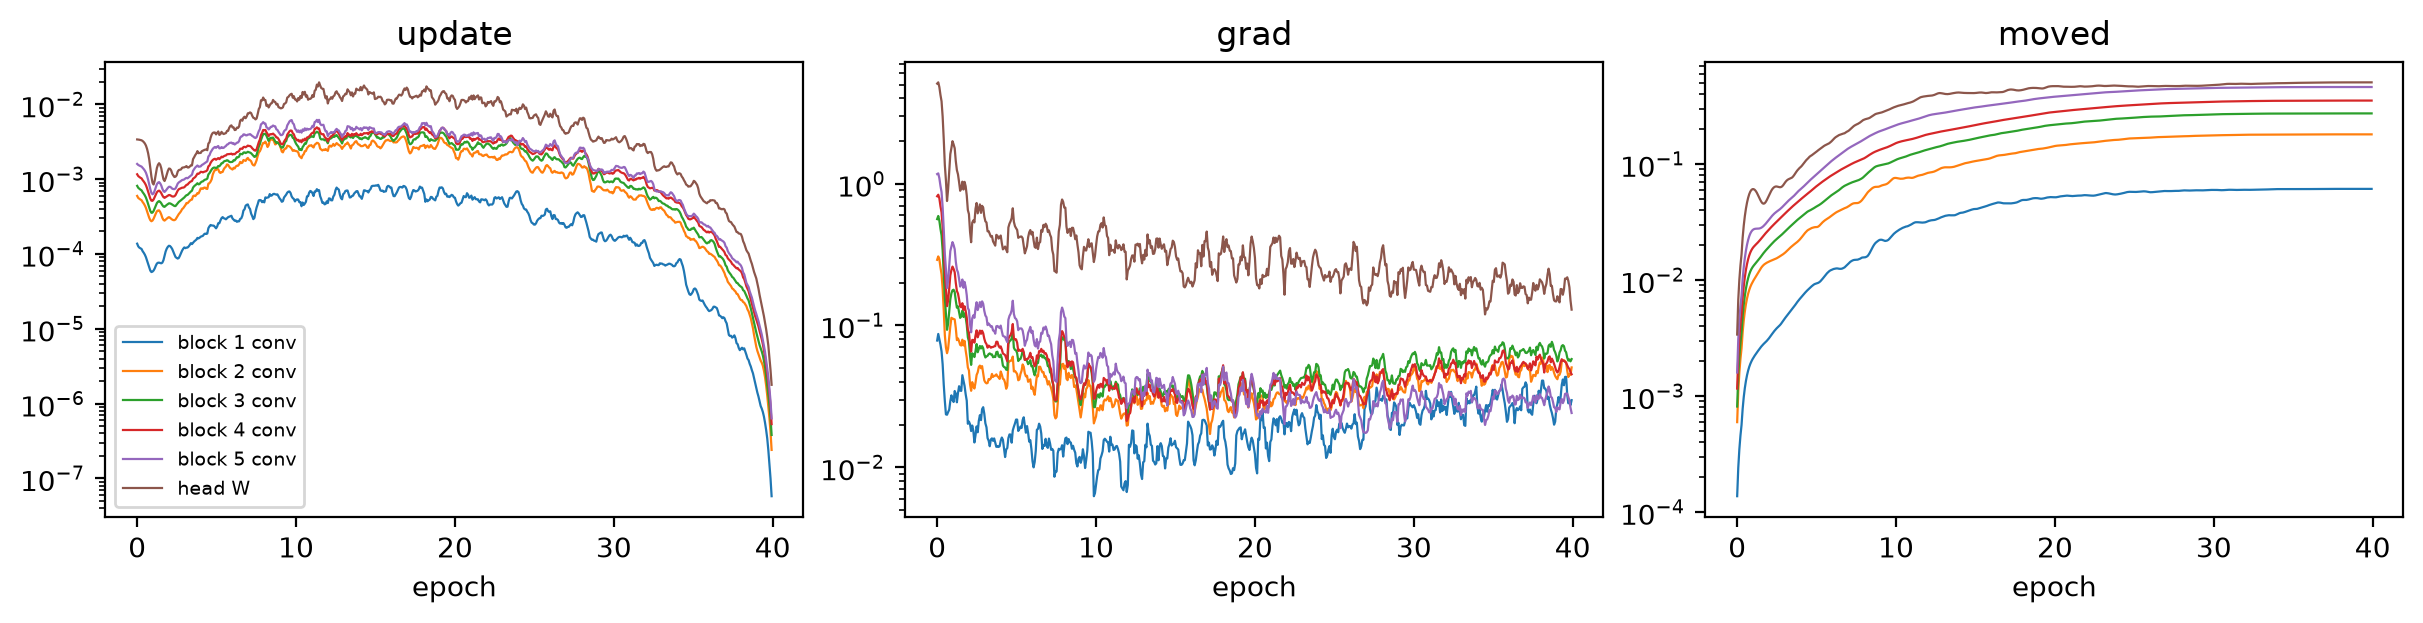

In [ ]:
#| fukudata
plot_params(runs['Fukushima only'], smooth=5);

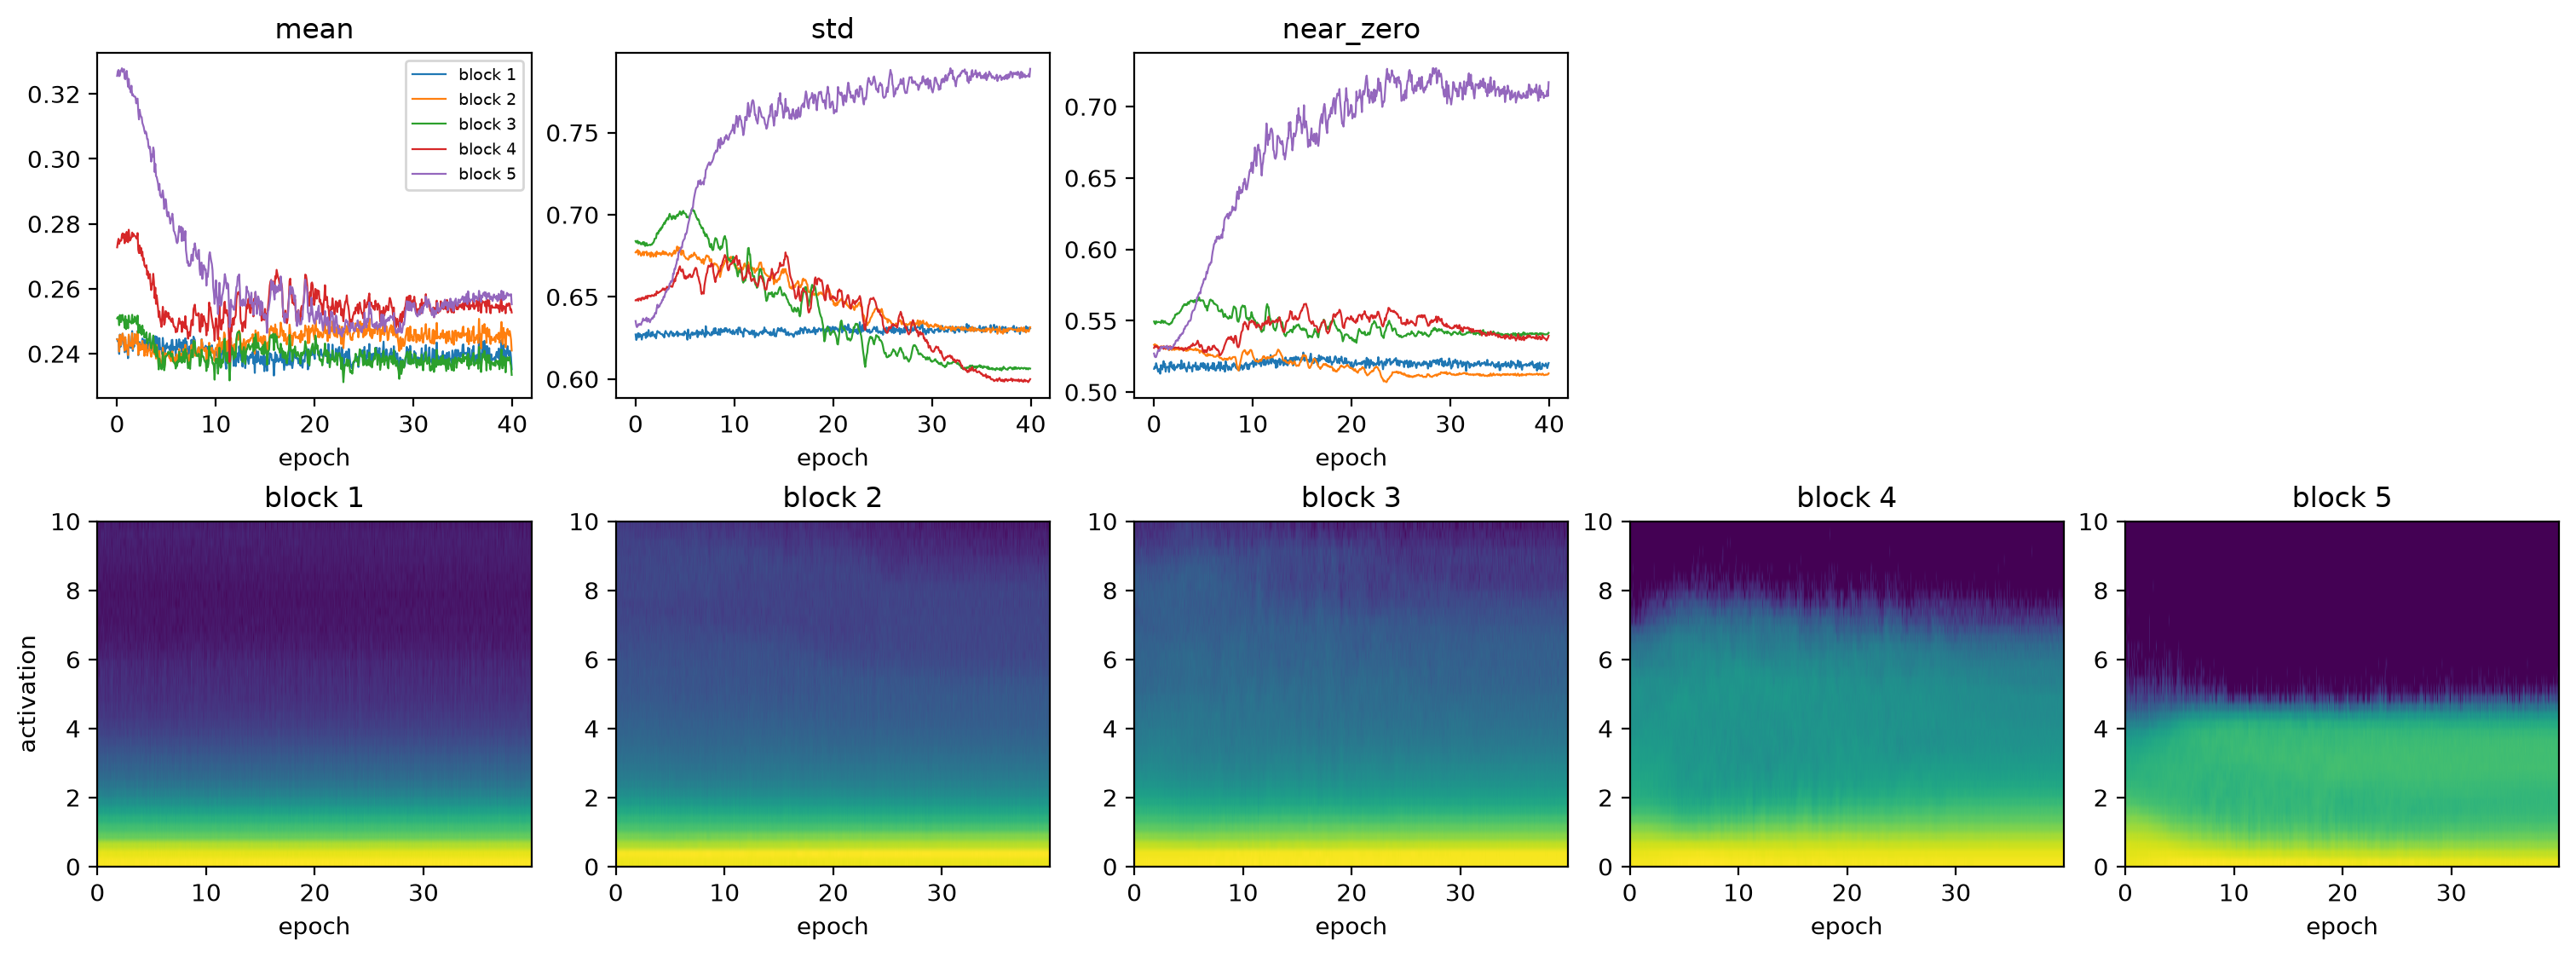

In [ ]:
#| fukudata
plot_acts(runs['Fukushima only']);

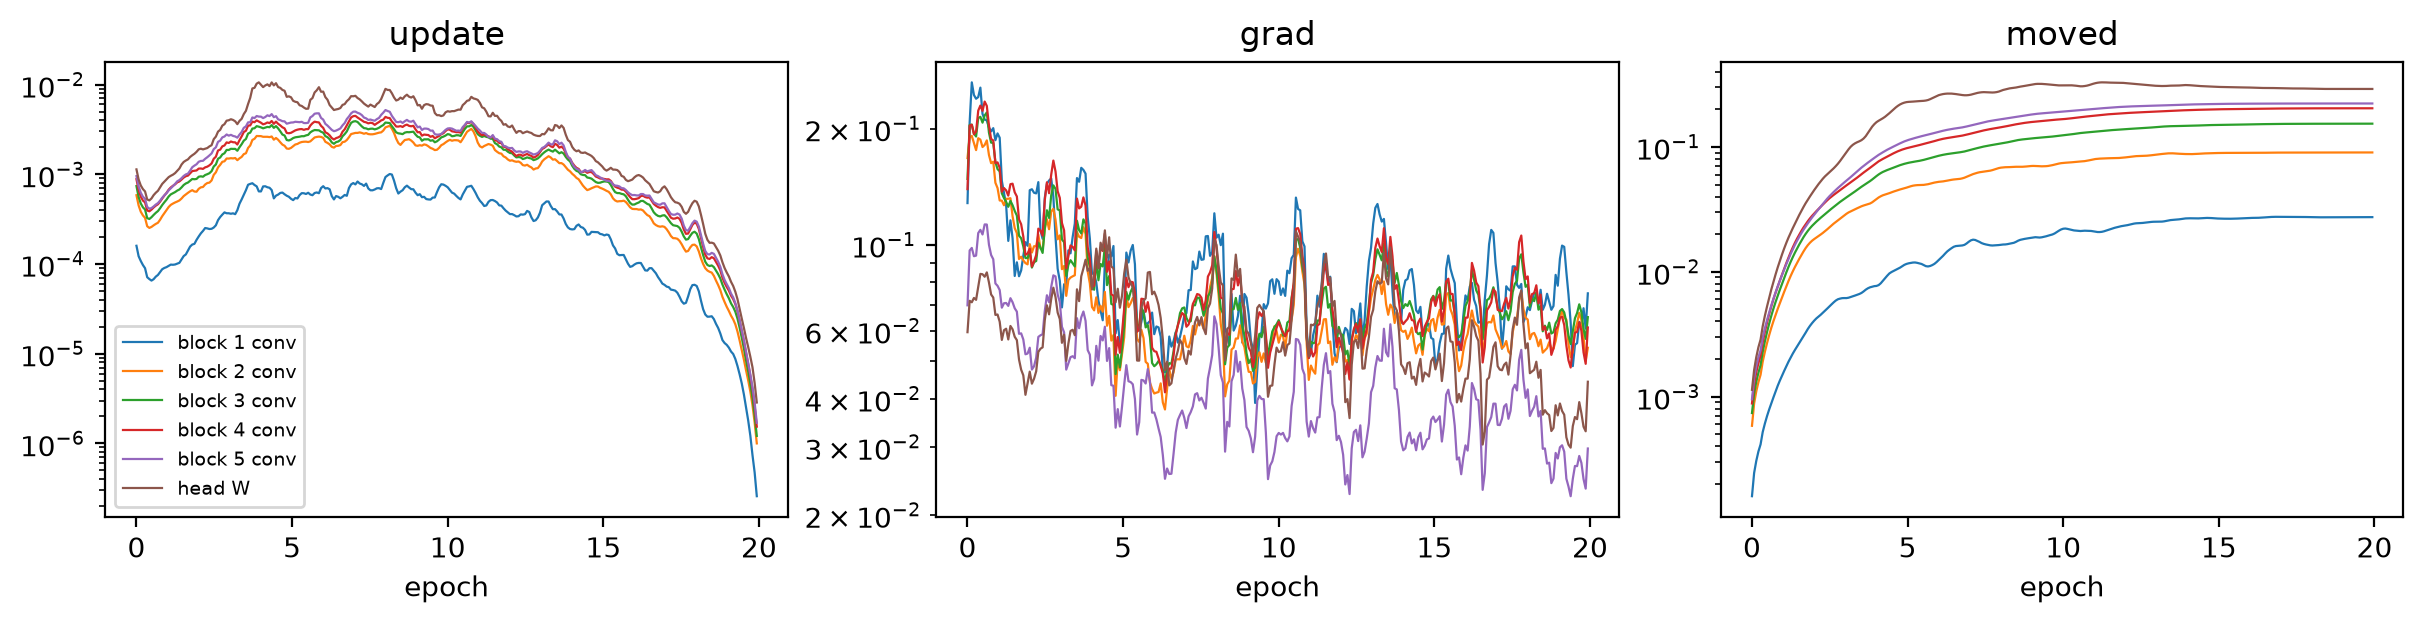

In [ ]:
#| fukudata
plot_params(runs['fully fine-tuned'], smooth=5);

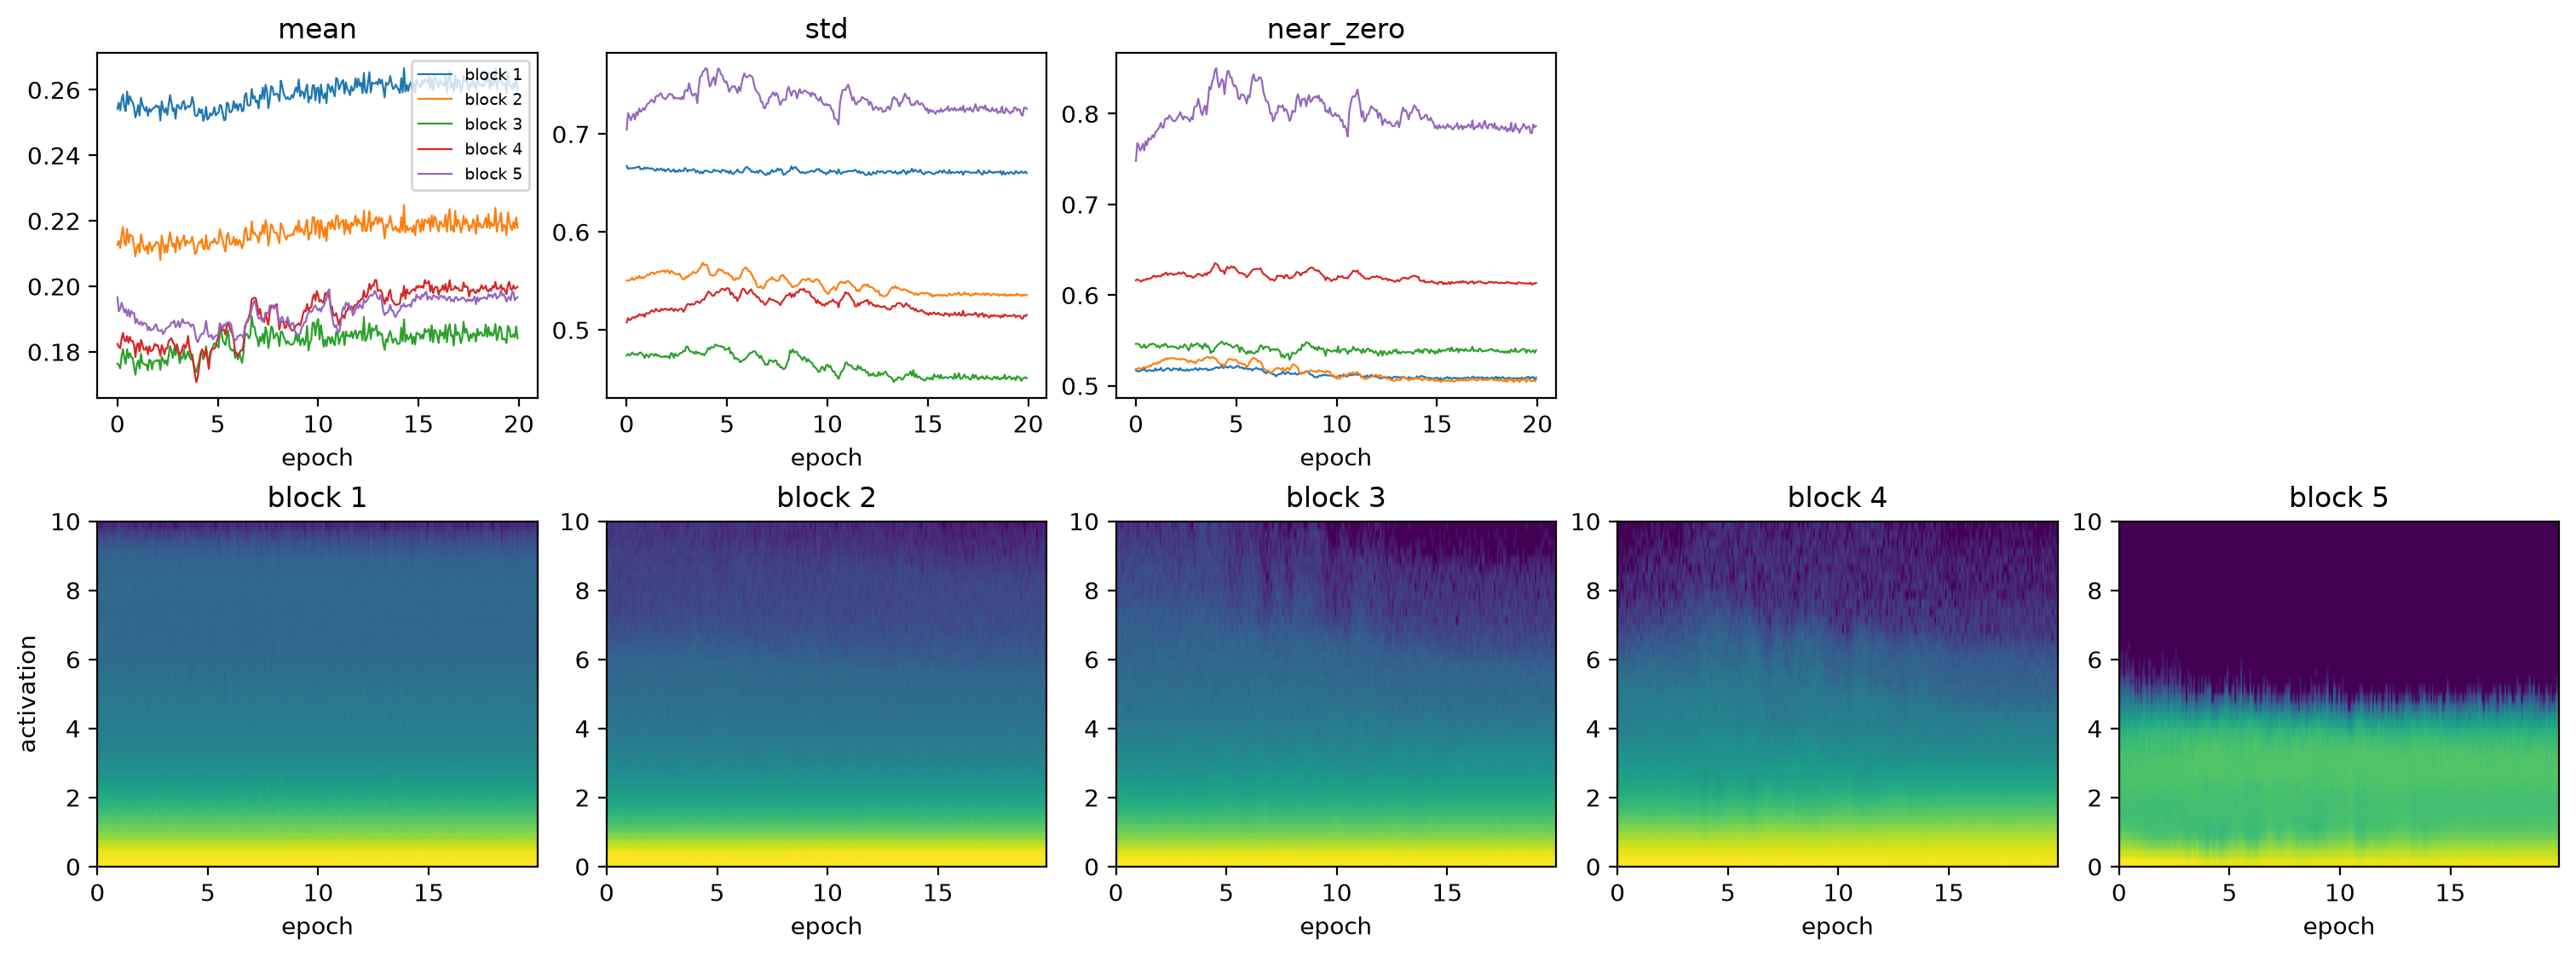

In [ ]:
#| fukudata
plot_acts(runs['fully fine-tuned']);

## Comparison

How far each parameter moved from its starting weights by the end of each run, ‖W − W₀‖/‖W₀‖. For the fully fine-tuned model, the start is the pretrained model. The BN shifts β and the head bias start at or near zero, so their relative distance means little, and the table leaves them out:

In [ ]:
#| fukudata
moved = pd.DataFrame({k: r['params'].groupby('param', sort=False)['moved'].last() for k, r in runs.items()})
moved[~moved.index.str.contains('β|head b')].round(3)

,OSSL,Fukushima only,fully fine-tuned
param,,,
block 1 conv,0.236,0.061,0.027
block 1 BN γ,0.147,0.036,0.016
block 2 conv,0.413,0.181,0.090
block 2 BN γ,0.192,0.069,0.023
block 3 conv,0.590,0.274,0.154
block 3 BN γ,0.165,0.052,0.033
block 4 conv,0.894,0.353,0.204
block 4 BN γ,0.140,0.053,0.025
block 5 conv,1.283,0.462,0.223


The median relative update per parameter over each run:

In [ ]:
#| fukudata
pd.DataFrame({k: r['params'].groupby('param', sort=False)['update'].median() for k, r in runs.items()}).loc[lambda d: d.index.str.contains('conv|head W')].map('{:.1e}'.format)

,OSSL,Fukushima only,fully fine-tuned
param,,,
block 1 conv,1.3e-04,3.1e-04,3.4e-04
block 2 conv,5.3e-04,1.4e-03,1.3e-03
block 3 conv,6.8e-04,1.9e-03,1.6e-03
block 4 conv,8.5e-04,2.3e-03,1.8e-03
block 5 conv,1.0e-03,2.7e-03,2.0e-03
head W,1.4e-03,5.7e-03,3.1e-03


Dead and linear channels of each model, per block, on 5,000 OSSL spectra and on all Fukushima spectra. The blocks have 16, 32, 64, 128 and 256 channels:

In [ ]:
#| fukudata
sub = np.random.default_rng(0).choice(len(Xo_d), 5000, replace=False)
acts = {(k, d): channel_activity(m, X) for k, m in models.items() for d, X in (('OSSL', Xo_d[sub]), ('Fukushima', Xf_d))}
activity_table(acts).drop(columns='channels').unstack(level=2)

dead             linear            
                              1  2  3  4  5      1  2  3  4  5
Fukushima only   Fukushima    0  0  0  0  0      0  0  0  0  0
                 OSSL         0  0  0  0  0      0  0  0  0  0
OSSL             Fukushima    0  0  0  0  0      0  0  0  0  0
                 OSSL         0  0  0  0  0      0  0  0  0  0
fully fine-tuned Fukushima    0  0  0  0  0      0  0  0  0  0
                 OSSL         0  0  0  0  0      0  0  0  0  0

## Findings

The CNN trains without the usual optimisation problems in all three runs. Gradients reach block 1. Activations neither collapse nor saturate. No channel of any block is dead (above 0.05 for less than 1% of spectra and positions) or linear (above 0.05 for more than 99%), on OSSL or on Fukushima spectra. At their peak, the relative updates of the convolutions in blocks 2 to 5 are 1–3·10⁻³ on OSSL (learning rate 10⁻³) and 2–4·10⁻³ on Fukushima (learning rate 3·10⁻³). Block 1's are several times smaller, for the reason in the next paragraph. In all three runs the updates fall to a few 10⁻⁶ at the end of the one-cycle schedule.

The differences between blocks in update size follow the initialisation, not the learning. In the first OSSL epoch, the relative updates of blocks 1 to 5 are in the ratio 1 : 4.2 : 5.7 : 8.1 : 11.3. The square roots of their fan-ins are in the ratio 1 : 4 : 5.7 : 8 : 11.3. How far each layer moves by the end of OSSL pretraining also rises from block 1 to block 5, but less steeply: 1 : 1.75 : 2.5 : 3.8 : 5.4. The initialisation explains part of why block 1 moves least, so that alone doesn't show that block 1 learns less.

Block 5 becomes sparse during training. Its share of activations ≤ 0.05 rises from 0.52 to 0.79 during OSSL pretraining, and from 0.53 to 0.72 when training on Fukushima from random weights. At the end, 15–17% of its activations are above 2.5, against at most 3.4% in blocks 1 to 4. Each of its channels responds strongly at a few positions and is off elsewhere. The global average pool then averages those positions.

Fine-tuning keeps the weights close to the pretrained ones. The convolutions and head move 0.03 to 0.29 of their norm, against 0.24 to 1.91 during pretraining from random weights. Compared with training from random weights, which runs twice as many epochs, fine-tuning moves each layer 0.44 to 0.58 as far. No layer takes a clearly larger share of the change.

In the first epoch of fine-tuning, the median gradient norm of block 1 is 0.21. At the end of OSSL pretraining it was 0.080, 2.6 times smaller. For the other layers the ratio is 1.6 to 2.2. This hints that the mismatch between OSSL and Fukushima is largest near the input, but the evidence is weak: the two gradients are measured at different points of different schedules.

On Fukushima, the training loss keeps falling after the validation loss levels off. When fine-tuning, the training loss halves from epoch 10 to epoch 19 (0.035 to 0.017) while the validation loss stays at 0.039–0.040. On OSSL, the validation R² still rises from 0.67 at epoch 10 to 0.79 at epoch 19. The test scores of the two Fukushima runs (R² 0.38 and 0.43) are close to the means in `03_kex` (0.37 and 0.42).

These diagnostics find no fault in how the network trains. They can't show whether it learns the right features for Fukushima. The CKA comparison and linear probes of `07`, and the wavenumber importance of `08`, address that.

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()